# Lecture: Comparing Distributions Across Groups

Compare real Billboard Hot 100 number-one songs using song length, total weeks at number one, and acousticness.

## Learning goals

- Compare center, spread, shape, overlap, and unusual values.
- Compare unequal groups with filled count histograms, box plots, and violin plots.
- Explain why equal-width box plots do not reveal sample size and why equal medians do not imply identical distributions.
- Apply the six-step workflow and support conclusions with numerical evidence.

## Data and context

Chris Dalla Riva compiled the *Billboard Hot 100 Number Ones Database* for his book *Uncharted Territory*. Our course CSV includes a prepared decade column and retains six documented fields from the supplied workbook and all 1,177 songs, including rows hidden by its saved artist filter. Its dates run from August 4, 1958 to January 11, 2025. Each row represents one song entry, not one chart week or one unique artist. Artists can appear more than once.

The `first_number_one_date` records when a song first reached number one. We use that date to assign decades, not its release date. The 1960s mean 1960–1969, the 1970s mean 1970–1979, the 1980s mean 1980–1989, the 1990s mean 1990–1999, the 2000s mean 2000–2009, and the 2010s mean 2010–2019. All three questions compare the six complete decades from 1960 through 2019. The partial 1950s and 2020s remain in the CSV but are excluded from these comparisons. The prepared CSV includes `decade` so students can group and filter directly. We retain every song in each selected decade, with no duration trimming or balancing of group sizes. The workbook is a historical snapshot; its cumulative chart totals do not update automatically.

### Data dictionary

| Feature | Meaning | Data type | Storage type |
| --- | --- | --- | --- |
| `song` | Song title | Categorical identifier together with artist | object or str |
| `artist` | Credited artist(s) | Categorical | object or str |
| `first_number_one_date` | First week the song reached number one | Temporal | datetime after parsing |
| `decade` | Decade of first reaching number one, prepared from the date | Categorical, ordered chronologically | object or str |
| `weeks_at_number_one` | Total consecutive and non-consecutive weeks at number one in this snapshot | Quantitative, discrete | int64 |
| `length_sec` | Recorded song length in seconds | Quantitative duration, recorded in whole seconds | int64 |
| `acousticness` | Spotify acousticness score on the workbook’s 0–100 scale; higher values indicate greater confidence that a recording is acoustic | Quantitative score | float64 (contains missing values) |

Acousticness is missing for two songs: “Rock On” by Michael Damian and “Lately” by Divine. The other course fields have no missing values. Keep both songs for song-length and chart-run comparisons; omit them only when analyzing acousticness, and report the usable group sizes. String and datetime storage types can vary with the Pandas version. Duration is elapsed time, not time of day; zero seconds is meaningful. A zero acousticness score is valid and differs from a missing value. The score does not measure a percentage of acoustic instruments.

**Source:** Chris Dalla Riva, *Billboard Hot 100 Number Ones Database*, supplied workbook and its Data Dictionary. See the local data README for field mappings and preparation details, and the creator's [book page](https://bio.site/uncharted_territory) and [newsletter](https://www.cantgetmuchhigher.com/) for context. These data describe number-one hits, not all released songs or all Hot 100 entries.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

## Prepare the notebook


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Research question 1: Song length across decades

## Step 1: Question

**Did the length of number 1 songs change from the 1960s to the 2010s?**

Compare the **1960s, 1970s, 1980s, 1990s, 2000s, and 2010s**. Some distributions may look similar and others different; describe the evidence without assuming every decade must differ.

### Discussion: predict the result

Predict whether the groups will differ in typical values or spread. Explain your reasoning.


Your prediction:


## Step 2: Data


In [2]:
songs_df = pd.read_csv("data/billboard_number_ones.csv", parse_dates=["first_number_one_date"])
songs_df.head()


,song,artist,first_number_one_date,weeks_at_number_one,length_sec,acousticness,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04,2,154,67.0,1950s
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18,5,219,98.0,1950s
2,Little Star,The Elegants,1958-08-25,1,163,87.0,1950s
3,It's All in the Game,Tommy Edwards,1958-09-29,6,156,4.0,1950s
4,It's Only Make Believe,Conway Twitty,1958-11-10,2,134,86.0,1950s


In [3]:
songs_df.tail()


,song,artist,first_number_one_date,weeks_at_number_one,length_sec,acousticness,decade
1172,Please Please Please,Sabrina Carpenter,2024-06-29,1,186,27.0,2020s
1173,A Bar Song (Tipsy),Shaboozey,2024-07-13,19,171,6.0,2020s
1174,Love Somebody,Morgan Wallen,2024-11-02,1,204,1.0,2020s
1175,squabble up,Kendrick Lamar,2024-12-07,1,157,2.0,2020s
1176,Die with a Smile,Bruno Mars & Lady Gaga,2025-01-11,2,251,31.0,2020s


In [4]:
songs_df.shape


(1177, 7)

In [5]:
songs_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1177 entries, 0 to 1176
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   song                   1177 non-null   object        
 1   artist                 1177 non-null   object        
 2   first_number_one_date  1177 non-null   datetime64[ns]
 3   weeks_at_number_one    1177 non-null   int64         
 4   length_sec             1177 non-null   int64         
 5   acousticness           1175 non-null   float64       
 6   decade                 1177 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 64.5+ KB


In [6]:
songs_df.isna().sum()


song                     0
artist                   0
first_number_one_date    0
weeks_at_number_one      0
length_sec               0
acousticness             2
decade                   0
dtype: int64

Use the `decade` column already included in the CSV to select the 1960s, 1970s, 1980s, 1990s, 2000s, and 2010s. Each observation is one song. Preview the labels alongside the dates and compare group sizes before interpreting the plots.


In [7]:
songs_df[["song", "first_number_one_date", "decade"]].head()


,song,first_number_one_date,decade
0,Poor Little Fool,1958-08-04,1950s
1,Nel Blu Dipinto Di Blu,1958-08-18,1950s
2,Little Star,1958-08-25,1950s
3,It's All in the Game,1958-09-29,1950s
4,It's Only Make Believe,1958-11-10,1950s


In [8]:
song_lengths_df = songs_df.loc[songs_df["decade"].isin(['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'])].copy()
song_lengths_df.shape


(1072, 7)

In [9]:
song_lengths_df["decade"].value_counts()


decade
1970s    253
1980s    231
1960s    203
1990s    140
2000s    129
2010s    116
Name: count, dtype: int64

## Step 3: Evidence

### Compare the means and medians


In [10]:
song_lengths_df.groupby("decade")["length_sec"].agg(["mean", "median"]).round(2)


,mean,median
decade,,
1960s,166.91,163.0
1970s,220.57,212.0
1980s,248.95,244.0
1990s,254.51,250.0
2000s,240.02,235.0
2010s,224.80,223.0


### Discussion: compare the centers

Which group has the higher mean and median? How large are the differences? Do the two measures tell a similar story?

### Why isn’t a mean or median enough?

A mean or median describes the center with one number. It does not show spread, shape, overlap, or unusual values. Groups with similar centers can have very different distributions; groups with different centers may still overlap. The mean is also more sensitive to extreme values than the median.

### Discussion: look beyond the center

What information could we miss by comparing only the means or medians?


### Compare distributions with a histogram

Use filled bars to compare the distributions. Seaborn chooses the bins automatically and uses shared bin edges for the groups in this plotting call. The vertical axis shows counts, so both group size and concentration affect bar heights.


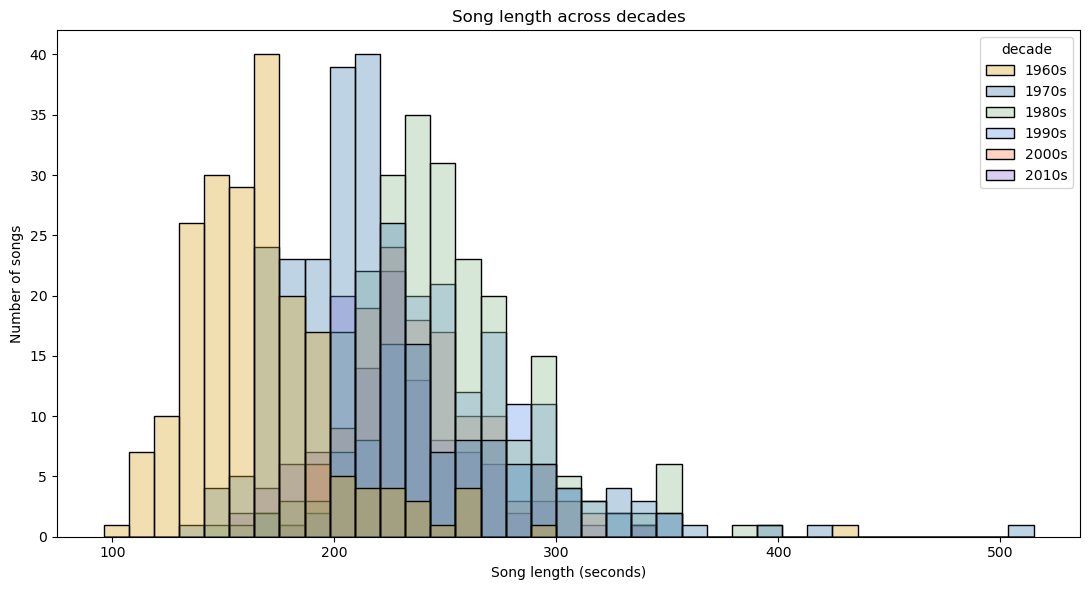

In [11]:
plt.figure(figsize=(11, 6))
sns.histplot(data=song_lengths_df, x="length_sec", hue="decade",
             hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], fill=True, alpha=0.35)
plt.title("Song length across decades")
plt.xlabel("Song length (seconds)")
plt.ylabel("Number of songs")
plt.tight_layout()
plt.show()


### Discussion: interpret the histogram

Using the histogram, visually estimate the center and spread of each group. Where do most observations fall? Describe shape, overlap, and any isolated values. How does the number of observations affect the heights of the bars?


Your visual estimates and observations:


### Calculate center and spread

Now use `.describe()` to check your visual estimates. Compare the mean, median (`50%`), standard deviation, quartiles, minimum, and maximum. The middle 50% lies between `25%` and `75%`; their difference is the interquartile range (IQR).


In [12]:
song_lengths_df.groupby("decade")["length_sec"].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
decade,,,,,,,,
1960s,203.0,166.91,36.29,96.0,144.0,163.0,182.0,426.0
1970s,253.0,220.57,49.00,141.0,191.0,212.0,235.0,515.0
1980s,231.0,248.95,38.52,147.0,225.0,244.0,268.0,391.0
1990s,140.0,254.51,34.09,170.0,231.0,250.0,277.0,346.0
2000s,129.0,240.02,30.41,179.0,218.0,235.0,256.0,338.0
2010s,116.0,224.80,32.55,157.0,203.5,223.0,242.0,343.0


### Discussion: compare estimates with calculations

How close were your visual estimates? Which numbers describe center, and which help describe spread? Would reporting only the mean or median adequately represent what the histogram shows?


### Compare distributions with a box plot

The box spans Q1 to Q3 (the middle 50%); its line marks the median. Whiskers reach the most extreme observations within 1.5 IQR of the box. More distant observations appear as individual points. These are potential outliers, not automatically errors. Equal-width boxes do not encode group size.


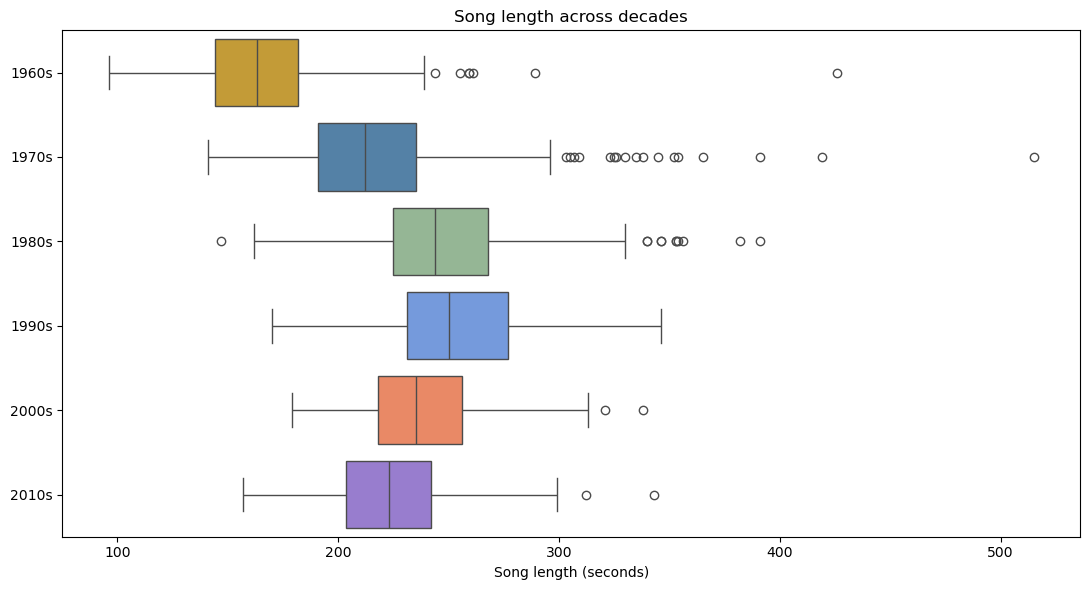

In [13]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=song_lengths_df, x="length_sec", y="decade",
             order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], hue="decade", hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'],
             palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], legend=False)
plt.title("Song length across decades")
plt.xlabel("Song length (seconds)")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Discussion: compare histograms and box plots

Compared with the histogram, which plot makes medians, quartiles, and potential outliers easier to identify? Which makes shape, peaks, gaps, and unequal group sizes easier to see? What information becomes harder to identify in each plot?

With six overlapping groups, which comparisons are obscured in the histogram? Which decades look similar, and which look different? Use the group counts when interpreting bar heights.


### Add a violin plot

A violin plot is one way to try to combine the good features of both histograms and box plots.

Its width shows a smoothed density estimate. `cut=0` keeps it within the observed range; smoothing still does not represent individual songs or prove multiple peaks.


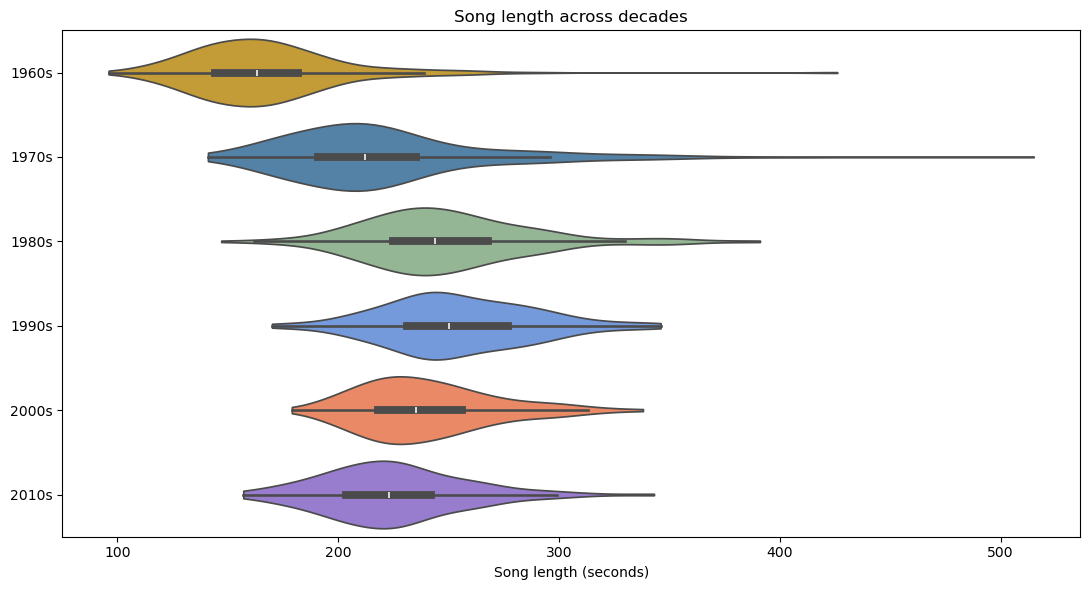

In [14]:
plt.figure(figsize=(11, 6))
sns.violinplot(data=song_lengths_df, x="length_sec", y="decade",
             order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], hue="decade", hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'],
             palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], legend=False, cut=0)
plt.title("Song length across decades")
plt.xlabel("Song length (seconds)")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Discussion: compare the violin plot

What does the violin reveal that the box plot does not? Which details are easier to read from the histogram? Does smoothing make any features less certain?


## Step 4: Check

### Discussion: check the evidence

Do the plotted centers and spreads agree with the summary table? Do the isolated points make sense relative to the quartiles and whiskers? Would it be reasonable to discard a record just because it appears beyond a whisker?

Check the earliest and latest first-number-one dates in each group. Inspect the entries with the largest values, including their song titles and artists. Are the units and the meanings of zero appropriate?


In [15]:
song_lengths_df.groupby("decade")["first_number_one_date"].agg(["min", "max", "count"])


,min,max,count
decade,,,
1960s,1960-01-04,1969-12-27,203
1970s,1970-01-03,1979-12-22,253
1980s,1980-01-05,1989-12-23,231
1990s,1990-01-20,1999-10-23,140
2000s,2000-01-15,2009-11-28,129
2010s,2010-01-02,2019-12-21,116


In [16]:
song_lengths_df.nlargest(5, "length_sec")[["song", "artist", "decade", "length_sec"]]


,song,artist,decade,length_sec
265,American Pie,Don McLean,1970s,515
207,Hey Jude,The Beatles,1960s,426
283,Papa Was a Rollin' Stone,The Temptations,1970s,419
422,Hotel California,Eagles,1970s,391
500,Rapture,Blondie,1980s,391


## Step 5: Conclusion

### Discussion: draw a conclusion

Answer the question using center, spread, and overlap, not just a single average. Compare with your prediction and limit the conclusion to the number-one songs in these decades.


## Step 6: Limitation

### Discussion: consider the limitations

Why can’t this result describe all released music or establish what caused the difference? Which decades look similar, and what evidence supports any differences? What other musical or historical information would help investigate possible explanations?


# Research question 2: Weeks at number one across decades

## Step 1: Question

**Did weeks at number one differ among songs first reaching number one in the 1960s, 1970s, 1980s, 1990s, 2000s, and 2010s?**

### Discussion: predict the result

Predict whether the groups will differ in typical values or spread. Explain your reasoning.


Your prediction:


## Step 2: Data


Reuse the original songs and decade labels. Select songs first reaching number one in the 1960s, 1970s, 1980s, 1990s, 2000s, or 2010s. Total weeks include non-consecutive runs and may extend beyond the decade of first reaching number one.


In [17]:
chart_runs_df = songs_df.loc[songs_df["decade"].isin(['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'])].copy()
chart_runs_df.shape


(1072, 7)

In [18]:
chart_runs_df["decade"].value_counts()


decade
1970s    253
1980s    231
1960s    203
1990s    140
2000s    129
2010s    116
Name: count, dtype: int64

## Step 3: Evidence


### Compare distributions with a histogram

Use filled bars to compare the distributions. Weeks are integer counts, so `discrete=True` centers shared bins on whole weeks. The vertical axis shows counts, so both group size and concentration affect bar heights.


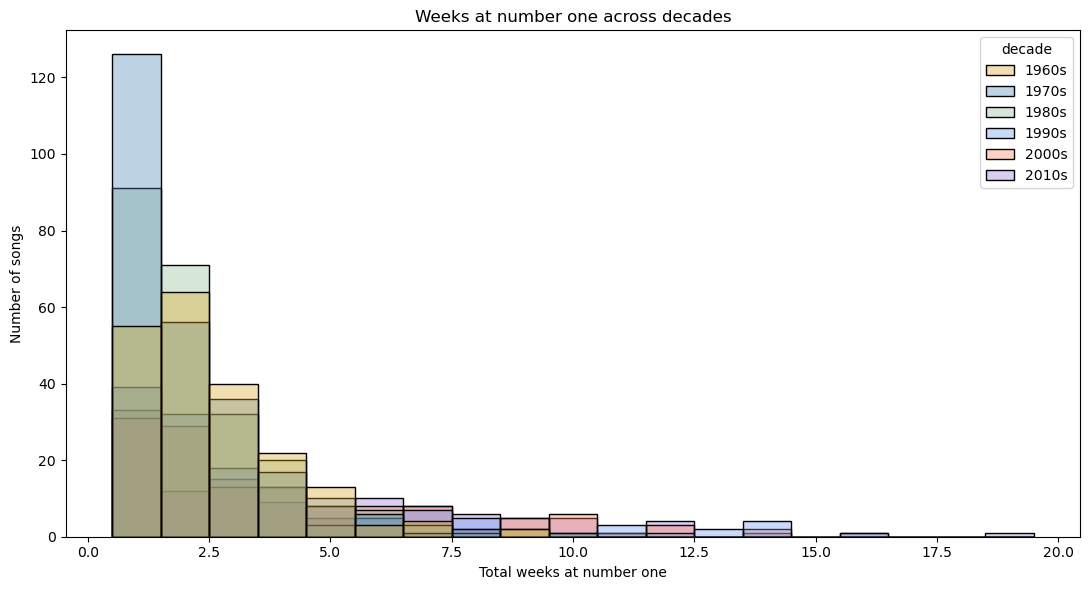

In [19]:
plt.figure(figsize=(11, 6))
sns.histplot(data=chart_runs_df, x="weeks_at_number_one", hue="decade",
             hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], fill=True, alpha=0.35, discrete=True)
plt.title("Weeks at number one across decades")
plt.xlabel("Total weeks at number one")
plt.ylabel("Number of songs")
plt.tight_layout()
plt.show()


### Discussion: interpret the histogram

Before calculating: visually estimate the center and spread of each group. Where do most observations fall? Describe shape, overlap, and any isolated values. How does the number of observations affect the heights of the bars?


Your visual estimates and observations:


### Calculate center and spread

Now use `.describe()` to check your visual estimates. Compare the mean, median (`50%`), standard deviation, quartiles, minimum, and maximum. The middle 50% lies between `25%` and `75%`; their difference is the interquartile range (IQR).


In [20]:
chart_runs_df.groupby("decade")["weeks_at_number_one"].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
decade,,,,,,,,
1960s,203.0,2.56,1.54,1.0,1.0,2.0,3.0,9.0
1970s,253.0,2.07,1.49,1.0,1.0,2.0,3.0,10.0
1980s,231.0,2.26,1.61,1.0,1.0,2.0,3.0,10.0
1990s,140.0,3.72,3.37,1.0,1.0,2.0,5.0,16.0
2000s,129.0,4.03,3.23,1.0,2.0,3.0,6.0,14.0
2010s,116.0,4.57,3.75,1.0,1.0,3.0,7.0,19.0


### Discussion: compare estimates with calculations

How close were your visual estimates? Which numbers describe center, and which help describe spread? Would reporting only the mean or median adequately represent what the histogram shows?


### Compare distributions with a box plot

The box spans Q1 to Q3 (the middle 50%); its line marks the median. Whiskers reach the most extreme observations within 1.5 IQR of the box. More distant observations appear as individual points. These are potential outliers, not automatically errors. Equal-width boxes do not encode group size.


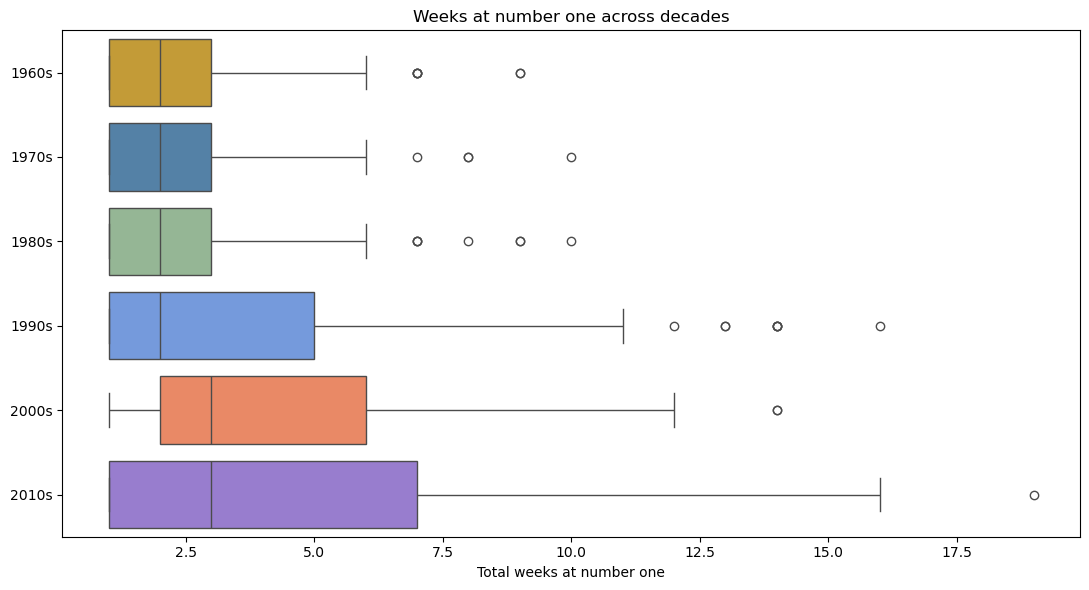

In [21]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=chart_runs_df, x="weeks_at_number_one", y="decade",
             order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], hue="decade", hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'],
             palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], legend=False)
plt.title("Weeks at number one across decades")
plt.xlabel("Total weeks at number one")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Discussion: compare histograms and box plots

Compared with the histogram, which plot makes medians, quartiles, and potential outliers easier to identify? Which makes shape, peaks, gaps, and unequal group sizes easier to see? What information becomes harder to identify in each plot?

With six overlapping groups, which comparisons are obscured in the histogram? Which decades look similar, and which look different? Use the group counts when interpreting bar heights.


## Step 4: Check

### Discussion: check the evidence

Do the plotted centers and spreads agree with the summary table? Do the isolated points make sense relative to the quartiles and whiskers? Would it be reasonable to discard a record just because it appears beyond a whisker?

Check the earliest and latest first-number-one dates in each group. Inspect the entries with the largest values, including their song titles and artists. Are the units and the meanings of zero appropriate?


In [22]:
chart_runs_df.groupby("decade")["first_number_one_date"].agg(["min", "max", "count"])


,min,max,count
decade,,,
1960s,1960-01-04,1969-12-27,203
1970s,1970-01-03,1979-12-22,253
1980s,1980-01-05,1989-12-23,231
1990s,1990-01-20,1999-10-23,140
2000s,2000-01-15,2009-11-28,129
2010s,2010-01-02,2019-12-21,116


In [23]:
chart_runs_df.nlargest(5, "weeks_at_number_one")[["song", "artist", "decade", "weeks_at_number_one"]]


,song,artist,decade,weeks_at_number_one
1085,Old Town Road,Lil Nas X ft. Billy Ray Cyrus,2010s,19
803,One Sweet Day,Mariah Carey & Boyz II Men,1990s,16
1064,Despacito,Luis Fonsi & Daddy Yankee ft. Justin Bieber,2010s,16
773,I Will Always Love You,Whitney Houston,1990s,14
790,I'll Make Love to You,Boyz II Men,1990s,14


## Step 5: Conclusion

### Discussion: draw a conclusion

Answer the question using center, spread, and overlap, not just a single average. Compare with your prediction and limit the conclusion to the number-one songs in these decades.


## Step 6: Limitation

### Discussion: consider the limitations

Why can’t this result describe all released music or establish what caused the difference? Which decades look similar, and what evidence supports any differences? What other musical or historical information would help investigate possible explanations?


# Research question 3: Acousticness across decades

## Step 1: Question

**Did the acousticness of number 1 songs change across the 1960s, 1970s, 1980s, 1990s, 2000s, and 2010s?**

Compare the **1960s, 1970s, 1980s, 1990s, 2000s, and 2010s**. Some distributions may look similar and others different; describe the evidence without assuming every decade must differ.

### Discussion: predict the result

Predict whether the groups will differ in typical values or spread. Explain your reasoning.


Your prediction:


## Step 2: Data


Reuse the original songs and select all six complete decades. Acousticness is a Spotify score supplied on a 0–100 scale in this workbook; higher values suggest a recording is more likely to be acoustic. It is not a percentage of instruments. Inspect missing scores and omit those rows only for this question. Zero is a valid score, not a missing-value code.


In [24]:
song_acousticness_df = songs_df.loc[songs_df["decade"].isin(['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'])].copy()


In [25]:
song_acousticness_df.loc[song_acousticness_df["acousticness"].isna(), ["song", "artist", "decade"]]


,song,artist,decade
690,Rock On,Michael Damian,1980s
834,Lately,Divine,1990s


In [26]:
song_acousticness_df = song_acousticness_df.dropna(subset=["acousticness"]).copy()


In [27]:
song_acousticness_df["decade"].value_counts()


decade
1970s    253
1980s    230
1960s    203
1990s    139
2000s    129
2010s    116
Name: count, dtype: int64

## Step 3: Evidence


### Compare distributions with a histogram

Use filled bars to compare the distributions. Seaborn chooses the bins automatically and uses shared bin edges for the groups in this plotting call. The vertical axis shows counts, so both group size and concentration affect bar heights.


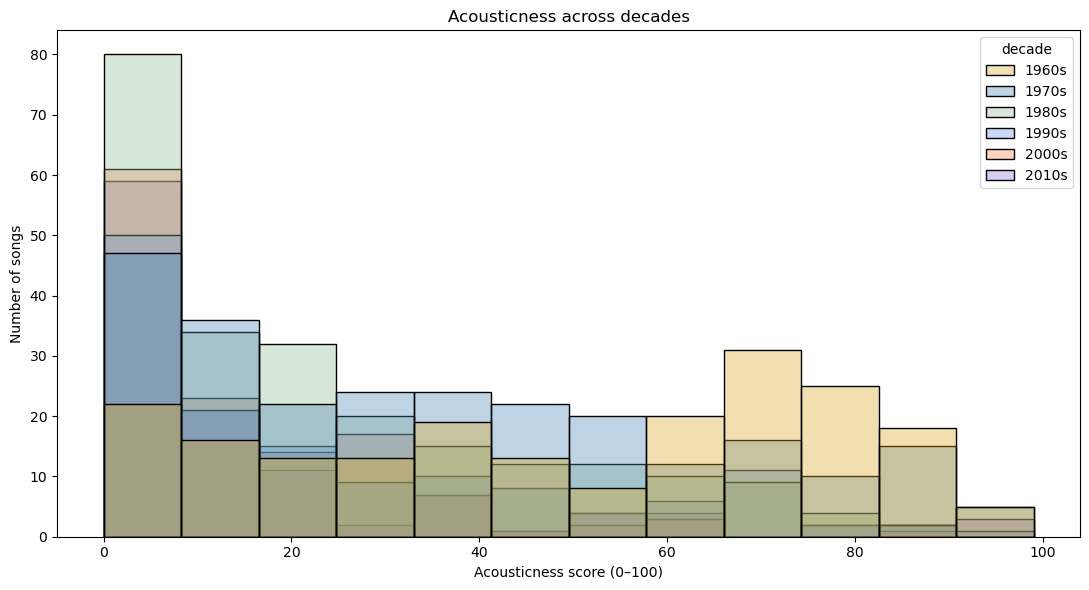

In [28]:
plt.figure(figsize=(11, 6))
sns.histplot(data=song_acousticness_df, x="acousticness", hue="decade",
             hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], fill=True, alpha=0.35)
plt.title("Acousticness across decades")
plt.xlabel("Acousticness score (0–100)")
plt.ylabel("Number of songs")
plt.tight_layout()
plt.show()


### Discussion: interpret the histogram

Before calculating: visually estimate the center and spread of each group. Where do most observations fall? Describe shape, overlap, and any isolated values. How does the number of observations affect the heights of the bars?


Your visual estimates and observations:


### Calculate center and spread

Now use `.describe()` to check your visual estimates. Compare the mean, median (`50%`), standard deviation, quartiles, minimum, and maximum. The middle 50% lies between `25%` and `75%`; their difference is the interquartile range (IQR).


In [29]:
song_acousticness_df.groupby("decade")["acousticness"].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
decade,,,,,,,,
1960s,203.0,49.27,28.13,0.0,24.50,55.0,73.0,99.0
1970s,253.0,35.97,27.24,0.0,11.00,31.0,56.0,96.0
1980s,230.0,23.54,21.99,0.0,5.25,17.0,35.0,88.0
1990s,139.0,24.86,25.15,0.0,4.00,15.0,41.0,98.0
2000s,129.0,14.53,15.68,0.0,3.00,9.0,23.0,89.0
2010s,116.0,17.72,23.43,0.0,2.00,8.0,20.5,93.0


### Discussion: compare estimates with calculations

How close were your visual estimates? Which numbers describe center, and which help describe spread? Would reporting only the mean or median adequately represent what the histogram shows?


### Compare distributions with a box plot

The box spans Q1 to Q3 (the middle 50%); its line marks the median. Whiskers reach the most extreme observations within 1.5 IQR of the box. More distant observations appear as individual points. These are potential outliers, not automatically errors. Equal-width boxes do not encode group size.


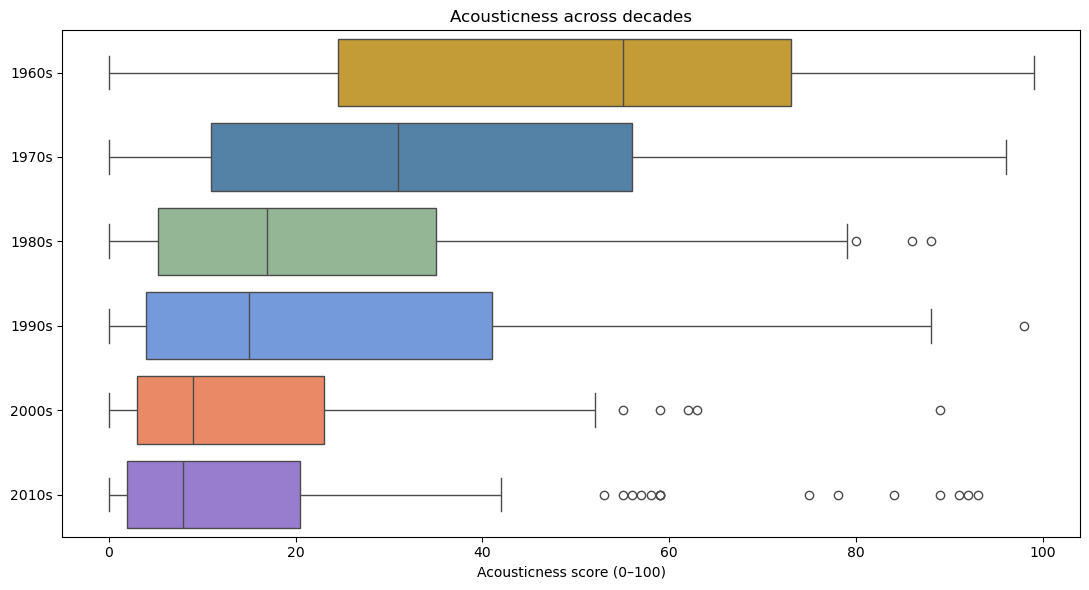

In [30]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=song_acousticness_df, x="acousticness", y="decade",
             order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'], hue="decade", hue_order=['1960s', '1970s', '1980s', '1990s', '2000s', '2010s'],
             palette=["goldenrod", "steelblue", "darkseagreen", "cornflowerblue", "coral", "mediumpurple"], legend=False)
plt.title("Acousticness across decades")
plt.xlabel("Acousticness score (0–100)")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Discussion: compare histograms and box plots

Compared with the histogram, which plot makes medians, quartiles, and potential outliers easier to identify? Which makes shape, peaks, gaps, and unequal group sizes easier to see? What information becomes harder to identify in each plot?

With six overlapping groups, which comparisons are obscured in the histogram? Which decades look similar, and which look different? Use the group counts when interpreting bar heights.


## Step 4: Check

### Discussion: check the evidence

Do the plotted centers and spreads agree with the summary table? Do the isolated points make sense relative to the quartiles and whiskers? Would it be reasonable to discard a record just because it appears beyond a whisker?

Check the earliest and latest first-number-one dates in each group. Inspect the entries with the largest values, including their song titles and artists. Are the units and the meanings of zero appropriate?


In [31]:
song_acousticness_df.groupby("decade")["first_number_one_date"].agg(["min", "max", "count"])


,min,max,count
decade,,,
1960s,1960-01-04,1969-12-27,203
1970s,1970-01-03,1979-12-22,253
1980s,1980-01-05,1989-12-23,230
1990s,1990-01-20,1999-10-23,139
2000s,2000-01-15,2009-11-28,129
2010s,2010-01-02,2019-12-21,116


In [32]:
song_acousticness_df.nsmallest(5, "acousticness")[["song", "artist", "decade", "acousticness"]]

,song,artist,decade,acousticness
81,Telstar,The Tornados,1960s,0.0
116,House of the Rising Sun,The Animals,1960s,0.0
157,Good Lovin',The Young Rascals,1960s,0.0
217,Honky Tonk Women,The Rolling Stones,1960s,0.0
294,Frankenstein,The Edgar Winter Group,1970s,0.0


In [33]:
song_acousticness_df.nlargest(5, "acousticness")[["song", "artist", "decade", "acousticness"]]


,song,artist,decade,acousticness
215,Love Theme from Romeo and Juliet,Henri Mancini & His Orchestra,1960s,99.0
820,Candle in the Wind 1997,Elton John,1990s,98.0
338,I Honestly Love You,Olivia Newton-John,1970s,96.0
25,Teen Angel,Mark Dinning,1960s,94.0
53,Quarter to Three,Gary U.S. Bonds,1960s,93.0


## Step 5: Conclusion

### Discussion: draw a conclusion

Answer the question using center, spread, and overlap, not just a single average. Compare with your prediction and limit the conclusion to the number-one songs in these decades.


## Step 6: Limitation

### Discussion: consider the limitations

Why can’t this result describe all released music or establish what caused the difference? Which decades look similar, and what evidence supports any differences? What other musical or historical information would help investigate possible explanations?


## Choosing a plot

| Plot | Easier to identify | More difficult to identify |
| --- | --- | --- |
| Filled count histogram | Shape, peaks, gaps, overlap, and differences in counts | Exact median and quartiles; smaller groups can be obscured |
| Equal-width box plot | Median, middle 50%, spread, and potential outliers | Sample size, modes, gaps, and detailed shape |

A center alone cannot describe a distribution. Report group sizes and units, compare center and spread, and inspect shape and overlap before drawing a conclusion.


## John Tukey and learning from data

The box plots in this lesson connect to John Tukey (1915–2000), a mathematician and statistician whose work helped shape modern data science and computer science.

- **Box plots and exploratory data analysis:** Tukey developed the box-and-whisker plot and championed exploratory data analysis (EDA), especially through his 1977 book *Exploratory Data Analysis*. His approach emphasized using graphs and numerical summaries to discover patterns, notice surprises, and ask better questions before committing to a formal model. Comparing entire distributions, rather than only averages, follows that approach.
- **Wartime fire control:** During World War II, Tukey worked at Princeton's Fire Control Research Office on mathematical problems involved in aiming weapons at moving targets. This work brought him into close contact with practical statistical problems and helped turn his attention toward data analysis.
- **The language of computing:** Tukey coined **bit**, short for *binary digit*. He is also widely credited with coining **software**, with his 1958 use of the word in print to describe computer programs being a landmark in computing terminology.

His career connects the visual tools we use to understand data with the mathematical and computational tools used to solve practical problems.


### Discussion

1. How does comparing a histogram with a box plot reflect Tukey's exploratory approach? What might you miss if you looked only at the mean?


**Further reading:** [American Philosophical Society's John W. Tukey Papers](https://as.amphilsoc.org/repositories/2/resources/2960) and [NIST's box plot guide](https://www.itl.nist.gov/div898/software/dataplot/tutorial/box_plot.htm).
